# 03 - Classification

Six classifiers plus a majority baseline, trained on applications filed 2000-2018 and tested on 2019-2022.

Steps: hyperparameter tuning with stratified 5-fold CV, choosing a decision threshold on a validation period,
final test evaluation, imbalance handling, preprocessing variants, feature importance and error analysis.

## Settings

In [1]:
FAST_MODE = True          # True: load the tuned parameters from outputs/best_params.json (minutes)
                          # False: run the full hyperparameter search again (about an hour)
TUNE_SAMPLE = 50_000      # training rows used for hyperparameter search
CV_FOLDS = 5
N_ITER = 8                # random search iterations per model
VAL_YEARS = (2017, 2018)  # validation period for choosing the threshold
RANDOM_STATE = 42

In [2]:
import sys, time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (precision_recall_curve, roc_curve, confusion_matrix,
                             average_precision_score, roc_auc_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from features import feature_groups
from modeling import make_preprocessor, make_models, PARAM_SPACES, best_f1_threshold, evaluate

FIG, OUT = ROOT / "figures", ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)

## 1. Data and split

In [3]:
feats = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
numeric, categorical, text = feature_groups(feats.columns)
X_cols = numeric + categorical + [text, "attorney_name"]

train = feats[feats["is_train"]].reset_index(drop=True)
test = feats[~feats["is_train"]].reset_index(drop=True)
y_train, y_test = train["failed"], test["failed"]

# validation features: same columns, but the failure rates of 2017-2018 are frozen at 2016,
# exactly like the test years are frozen at 2018 (built in notebook 02)
feats_val = pd.read_parquet(ROOT / "data" / "processed" / "features_val.parquet")
fit_part = feats_val[feats_val["filing_year"] < VAL_YEARS[0]].reset_index(drop=True)
val_part = feats_val[feats_val["filing_year"].between(*VAL_YEARS)].reset_index(drop=True)

pd.DataFrame({
    "rows": [len(train), len(fit_part), len(val_part), len(test)],
    "failure_rate": [y_train.mean(), fit_part["failed"].mean(), val_part["failed"].mean(), y_test.mean()],
}, index=["train 2000-2018", "  fit 2000-2016", "  validation 2017-2018", "test 2019-2022"]).round(4)

,rows,failure_rate
train 2000-2018,180442,0.1528
fit 2000-2016,159263,0.1540
validation 2017-2018,21179,0.1437
test 2019-2022,47047,0.1394


## 2. Preprocessing

Inside every pipeline (so it is fit on training folds only):
numeric columns are standardized, categorical columns one-hot encoded, and the English goods description goes
through TF-IDF (20,000 terms, English stop words removed) and TruncatedSVD to 50 components.
Trees don't need scaling, but it doesn't hurt them, so all models share the same preprocessing.

In [4]:
def make_pipeline(model, **pre_kwargs):
    return Pipeline([("pre", make_preprocessor(numeric, categorical, text, **pre_kwargs)), ("model", model)])

pre = make_preprocessor(numeric, categorical, text).fit(train.head(20000))
print("Model input size:", len(pre.get_feature_names_out()), "columns")

Model input size: 154 columns


## 3. Hyperparameter tuning

Random search with stratified 5-fold CV on a stratified sample of the training set, scored by PR-AUC
(average precision), which suits the 15% minority class better than accuracy.
With `FAST_MODE = True` the search is skipped and the saved parameters are loaded.
(The saved parameters come from the search run before `filing_year` was removed from the features.)

In [5]:
tune, _ = train_test_split(train, train_size=TUNE_SAMPLE, stratify=y_train, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
models = make_models()

params_file = OUT / "best_params.json"
if FAST_MODE and params_file.exists():
    best_params = json.loads(params_file.read_text())
    tuning = pd.DataFrame([{"model": n, "best params": {k.replace("model__", ""): v for k, v in p.items()}}
                           for n, p in best_params.items()])
    print("FAST_MODE: loaded parameters from", params_file.relative_to(ROOT))
    display(tuning)

best_params_search, tuning_rows = {}, []
for name, space in ({} if FAST_MODE and params_file.exists() else PARAM_SPACES).items():
    start = time.time()
    n_combos = int(np.prod([len(v) for v in space.values()]))
    search = RandomizedSearchCV(make_pipeline(models[name]), space, n_iter=min(N_ITER, n_combos),
                                scoring="average_precision", cv=cv, random_state=RANDOM_STATE, n_jobs=1)
    search.fit(tune[X_cols], tune["failed"])
    best_params_search[name] = search.best_params_
    i = search.best_index_
    tuning_rows.append({"model": name,
                        "CV PR-AUC": f"{search.cv_results_['mean_test_score'][i]:.3f} ± {search.cv_results_['std_test_score'][i]:.3f}",
                        "best params": {k.replace('model__', ''): v for k, v in search.best_params_.items()},
                        "minutes": round((time.time() - start) / 60, 1)})
if tuning_rows:
    best_params = best_params_search
    params_file.write_text(json.dumps(best_params, indent=2))
    tuning = pd.DataFrame(tuning_rows)
    display(tuning)

FAST_MODE: loaded parameters from outputs/best_params.json


,model,best params
0,Logistic Regression,{'C': 10}
1,Decision Tree,"{'min_samples_leaf': 100, 'max_depth': 20}"
2,Random Forest,"{'min_samples_leaf': 5, 'max_features': 0.3, '..."
3,LightGBM,"{'num_leaves': 127, 'n_estimators': 600, 'min_..."
4,KNN,"{'weights': 'distance', 'n_neighbors': 51}"
5,MLP,"{'learning_rate_init': 0.003, 'hidden_layer_si..."


## 4. Final models

For each model: fit with the best parameters on 2000-2016, measure PR-AUC and choose the threshold that maximizes F1
on 2017-2018, then refit on all of 2000-2018 and evaluate once on the test set (2019-2022) with that threshold.
The best model is chosen by its **validation** PR-AUC; the test set is only used for the final report.

In [6]:
def fit_with_threshold(pipeline_factory):
    """Pick the F1 threshold on the validation years, then refit on the full training set."""
    pipe = pipeline_factory()
    pipe.fit(fit_part[X_cols], fit_part["failed"])
    val_proba = pipe.predict_proba(val_part[X_cols])[:, 1]
    threshold = best_f1_threshold(val_part["failed"], val_proba)
    val_pr_auc = average_precision_score(val_part["failed"], val_proba)
    pipe = pipeline_factory()
    pipe.fit(train[X_cols], y_train)
    return pipe, threshold, val_pr_auc

final, probas, results = {}, {}, []
for name, model in models.items():
    start = time.time()
    factory = lambda m=model, n=name: make_pipeline(clone(m)).set_params(**best_params.get(n, {}))
    if name.startswith("Baseline"):
        pipe, threshold, val_pr_auc = factory().fit(train[X_cols], y_train), 0.5, val_part["failed"].mean()
    else:
        pipe, threshold, val_pr_auc = fit_with_threshold(factory)
    final[name] = pipe
    probas[name] = pipe.predict_proba(test[X_cols])[:, 1]
    results.append({"model": name, "val PR-AUC": val_pr_auc, **evaluate(y_test, probas[name], threshold),
                    "minutes": round((time.time() - start) / 60, 1)})

results = pd.DataFrame(results).set_index("model").round(3)
results.to_csv(OUT / "classification_test_results.csv")
best_name = results.drop(index="Baseline (majority)")["val PR-AUC"].idxmax()
print("Best model on the validation years:", best_name)
results.sort_values("val PR-AUC", ascending=False)

Best model on the validation years: Random Forest


,val PR-AUC,ROC-AUC,PR-AUC,precision,recall,F1,threshold,minutes
model,,,,,,,,
Random Forest,0.419,0.728,0.348,0.339,0.399,0.366,0.446,9.3
LightGBM,0.416,0.723,0.343,0.315,0.422,0.360,0.166,1.0
MLP,0.350,0.705,0.295,0.254,0.533,0.344,0.164,0.9
Logistic Regression,0.348,0.704,0.281,0.280,0.423,0.337,0.606,0.5
Decision Tree,0.324,0.675,0.281,0.265,0.402,0.320,0.592,0.8
KNN,0.299,0.652,0.259,0.248,0.386,0.302,0.195,1.0
Baseline (majority),0.144,0.500,0.139,0.000,0.000,0.000,0.500,0.2


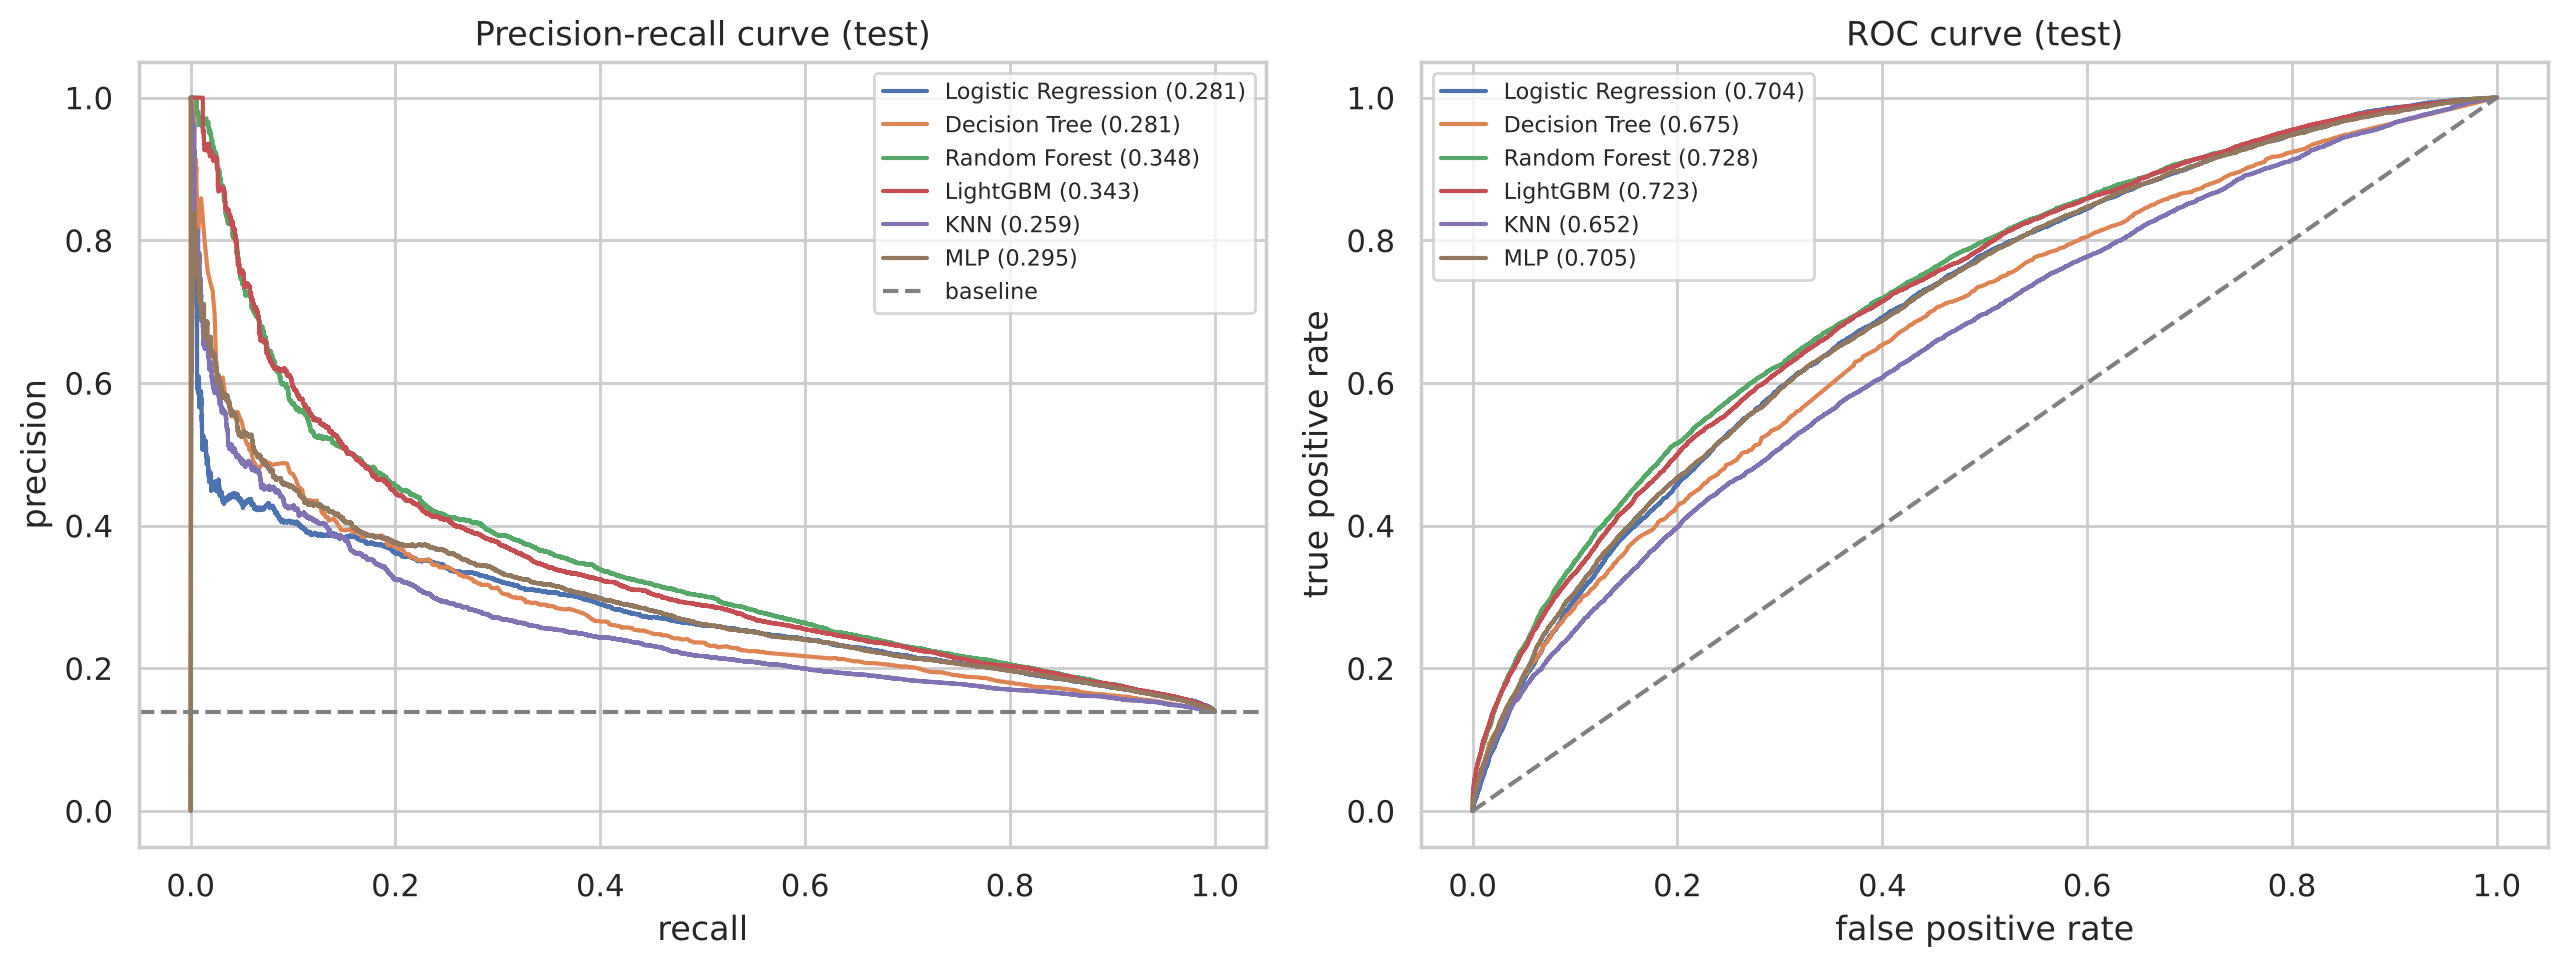

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    if name.startswith("Baseline"):
        continue
    prec, rec, _ = precision_recall_curve(y_test, p)
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(rec, prec, label=f"{name} ({results.loc[name, 'PR-AUC']:.3f})")
    axes[1].plot(fpr, tpr, label=f"{name} ({results.loc[name, 'ROC-AUC']:.3f})")
axes[0].axhline(y_test.mean(), color="grey", ls="--", label="baseline")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall curve (test)")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "classification_curves.png", dpi=120)
plt.show()

**Results.** Random Forest has the best validation PR-AUC (0.419, LightGBM 0.416), so it is the chosen model.
On the test set it reaches PR-AUC 0.35 and ROC-AUC 0.73, compared with 0.14 for the baseline. At the threshold chosen
on 2017-2018 it catches 40% of the failures with 34% precision. LightGBM is almost the same; Logistic Regression,
the Decision Tree and the MLP are in the middle, and KNN is the weakest. The order of the models is the same on validation and test.

Two gaps are worth noting. The CV scores in section 3 (PR-AUC up to 0.55, random folds over all years) are higher than the
validation scores (about 0.42, a later period), which are higher than the test scores (0.35, the latest period).
The further the evaluation is from the training years, the lower the score. Part of the signal doesn't carry over to
new years, which is why the evaluation has to be done on a time split.

Removing `filing_year` from the features barely changed the test scores (Random Forest PR-AUC 0.350 before, 0.348 now),
so the model wasn't really depending on it, and now it can't.

## 5. Handling the imbalance

Compared on the two strongest model types: no adjustment, class weights, and SMOTE.
SMOTE runs inside the pipeline after preprocessing, so it only creates synthetic rows from the training data.
Each strategy is reported at the default 0.5 threshold and at the F1 threshold chosen on the validation years.

In [8]:
def strategy_pipeline(name, strategy):
    model = clone(models[name])
    params = {k.replace("model__", ""): v for k, v in best_params[name].items()}
    model.set_params(**params, class_weight="balanced" if strategy == "class weights" else None)
    if strategy == "SMOTE":
        return ImbPipeline([("pre", make_preprocessor(numeric, categorical, text)),
                            ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])
    return Pipeline([("pre", make_preprocessor(numeric, categorical, text)), ("model", model)])

imbalance_rows = []
for name in ["LightGBM", "Logistic Regression"]:
    for strategy in ["none", "class weights", "SMOTE"]:
        pipe, threshold, _ = fit_with_threshold(lambda: strategy_pipeline(name, strategy))
        p = pipe.predict_proba(test[X_cols])[:, 1]
        for label, thr in [("0.5", 0.5), ("tuned", threshold)]:
            m = evaluate(y_test, p, thr)
            imbalance_rows.append({"model": name, "strategy": strategy, "threshold": label,
                                   **{k: m[k] for k in ["ROC-AUC", "PR-AUC", "precision", "recall", "F1"]},
                                   "threshold value": round(thr, 3)})
imbalance = pd.DataFrame(imbalance_rows).round(3)
imbalance

,model,strategy,threshold,ROC-AUC,PR-AUC,precision,recall,F1,threshold value
0,LightGBM,none,0.5,0.723,0.343,0.567,0.113,0.188,0.500
1,LightGBM,none,tuned,0.723,0.343,0.315,0.422,0.360,0.166
2,LightGBM,class weights,0.5,0.722,0.341,0.364,0.304,0.331,0.500
3,LightGBM,class weights,tuned,0.722,0.341,0.313,0.429,0.362,0.386
4,LightGBM,SMOTE,0.5,0.723,0.341,0.527,0.128,0.206,0.500
5,LightGBM,SMOTE,tuned,0.723,0.341,0.289,0.469,0.358,0.163
6,Logistic Regression,none,0.5,0.702,0.282,0.452,0.052,0.093,0.500
7,Logistic Regression,none,tuned,0.702,0.282,0.261,0.484,0.339,0.195
8,Logistic Regression,class weights,0.5,0.704,0.281,0.240,0.604,0.343,0.500
9,Logistic Regression,class weights,tuned,0.704,0.281,0.280,0.423,0.337,0.606


**Imbalance.** The ranking quality (PR-AUC, ROC-AUC) is almost the same for all three strategies.
What changes is the threshold: LightGBM without any adjustment catches only 11% of the failures at 0.5, and 42% once the
threshold is tuned. After tuning, all strategies reach a similar F1 (0.34-0.36). SMOTE adds training time
without improving anything, so tuning the threshold is the simplest fix here.

## 6. Preprocessing variants

Threshold-free metrics on the test set for different input choices:
the full feature set, without the goods text, with one-hot columns for the 100 most frequent attorneys instead
of the attorney failure rate, and without any history features.

In [9]:
history = ["owner_fail_rate", "attorney_fail_rate", "owner_prior_filings", "attorney_prior_filings"]
variants = {
    "full": dict(num=numeric, text=text, onehot=False),
    "no goods text": dict(num=numeric, text=None, onehot=False),
    "attorney one-hot instead of rate": dict(num=[c for c in numeric if c != "attorney_fail_rate"], text=text, onehot=True),
    "no history features": dict(num=[c for c in numeric if c not in history], text=text, onehot=False),
}
variant_rows = []
for name in ["LightGBM", "Logistic Regression"]:
    for vname, v in variants.items():
        pipe = Pipeline([("pre", make_preprocessor(v["num"], categorical, v["text"], attorney_onehot=v["onehot"])),
                         ("model", clone(models[name]))]).set_params(**best_params[name])
        pipe.fit(train[X_cols], y_train)
        p = pipe.predict_proba(test[X_cols])[:, 1]
        variant_rows.append({"model": name, "variant": vname,
                             "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})
variants_table = pd.DataFrame(variant_rows).round(3)
variants_table.pivot(index="variant", columns="model", values=["PR-AUC", "ROC-AUC"])

PR-AUC                      ROC-AUC  \
model                            LightGBM Logistic Regression LightGBM   
variant                                                                  
attorney one-hot instead of rate    0.345               0.282    0.724   
full                                0.343               0.281    0.723   
no goods text                       0.297               0.277    0.702   
no history features                 0.317               0.263    0.699   

                                                      
model                            Logistic Regression  
variant                                               
attorney one-hot instead of rate               0.706  
full                                           0.704  
no goods text                                  0.699  
no history features                            0.684

**Variants.** Removing the goods text hurts LightGBM the most (PR-AUC 0.343 -> 0.297), and removing the history
features hurts both models (0.343 -> 0.317, 0.281 -> 0.263). One-hot columns for the top 100 attorneys work about as well as
the single failure-rate column (0.345 vs 0.343), so we keep the rate, which is one column instead of 100.

## 7. What drives the predictions

Permutation importance on the test set for the best model: each input column is shuffled and the drop in
PR-AUC is measured (the goods text is shuffled as one column). Groups of binary columns (Nice classes, Vienna codes) are shuffled together. Then SHAP values show the direction of the effects.

Best model (chosen on validation): Random Forest


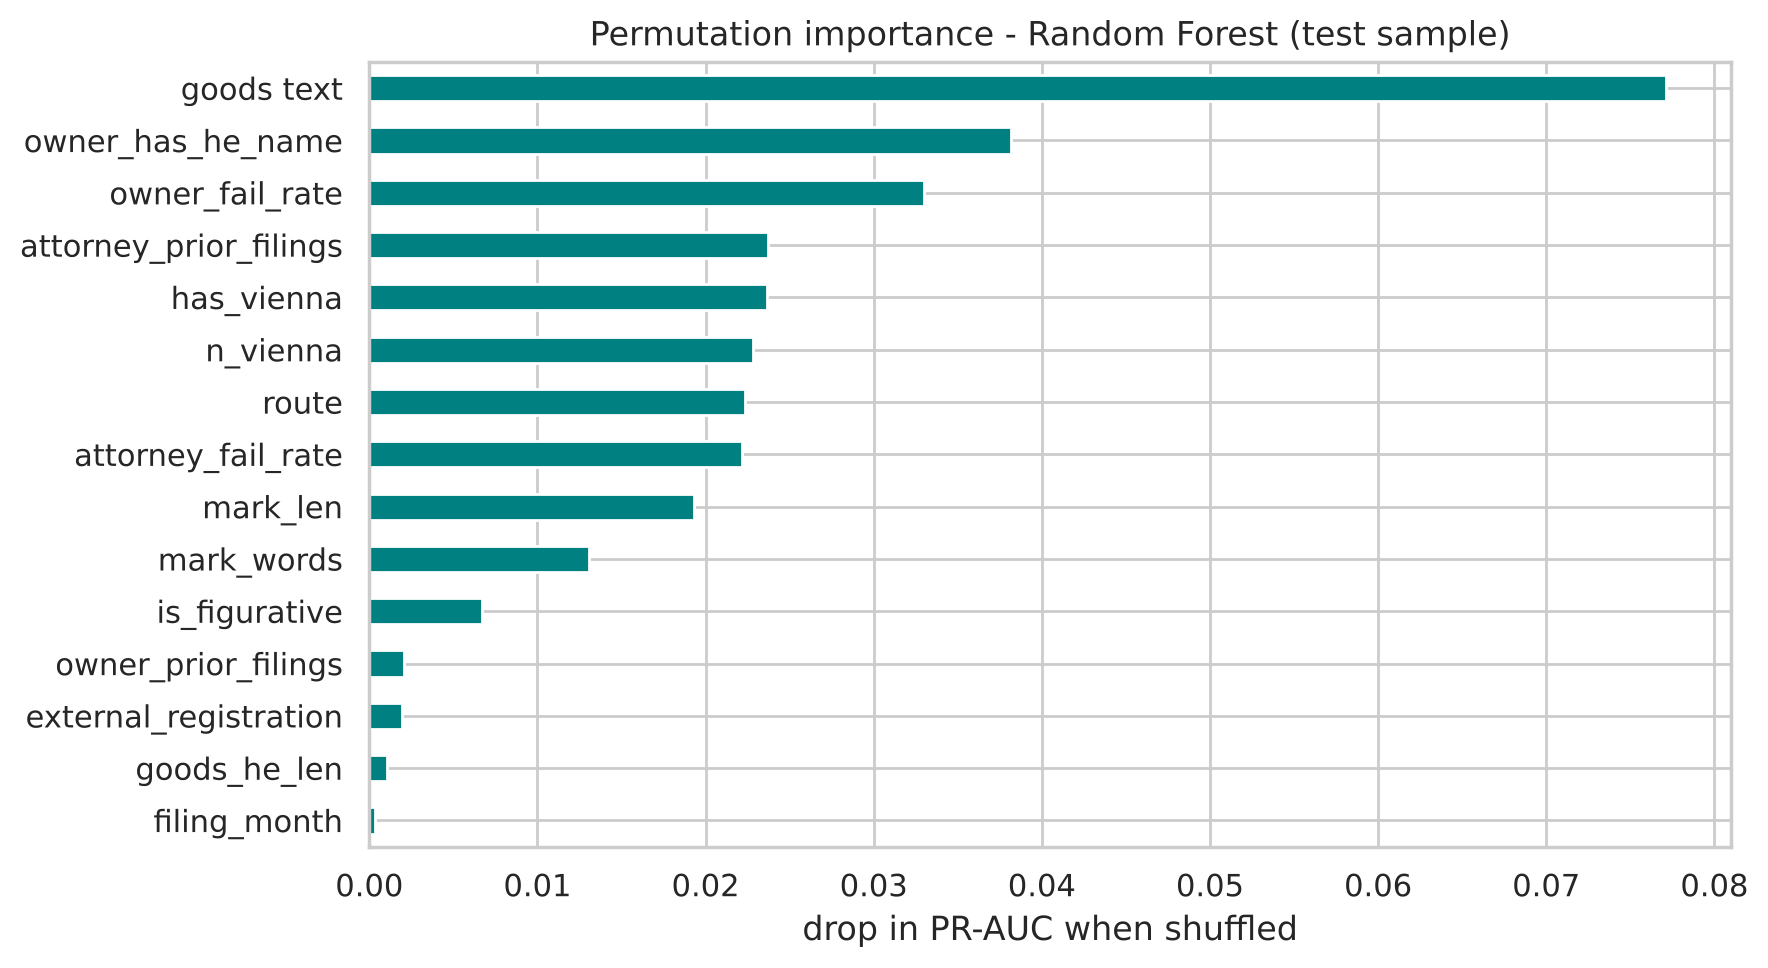

In [10]:
best = final[best_name]
print("Best model (chosen on validation):", best_name)

sample = test.sample(15_000, random_state=RANDOM_STATE).reset_index(drop=True)
groups = {c: [c] for c in numeric if not c.startswith(("nice_", "vienna_"))}
groups.update({c: [c] for c in categorical})
groups["goods text"] = [text]
groups["Nice classes (all)"] = [c for c in numeric if c.startswith("nice_")]
groups["Vienna codes (all)"] = [c for c in numeric if c.startswith("vienna_")]

rng = np.random.default_rng(RANDOM_STATE)
base_score = average_precision_score(sample["failed"], best.predict_proba(sample[X_cols])[:, 1])
drops = {}
for gname, cols in groups.items():
    scores = []
    for _ in range(3):
        shuffled = sample.copy()
        order = rng.permutation(len(sample))
        shuffled[cols] = sample[cols].to_numpy()[order]   # shuffle the group's columns together
        scores.append(average_precision_score(sample["failed"], best.predict_proba(shuffled[X_cols])[:, 1]))
    drops[gname] = base_score - np.mean(scores)
imp = pd.Series(drops)
imp = imp.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
imp[::-1].plot.barh(ax=ax, color="teal")
ax.set_xlabel("drop in PR-AUC when shuffled")
ax.set_title(f"Permutation importance - {best_name} (test sample)")
plt.tight_layout()
plt.savefig(FIG / "permutation_importance.png", dpi=120)
plt.show()

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


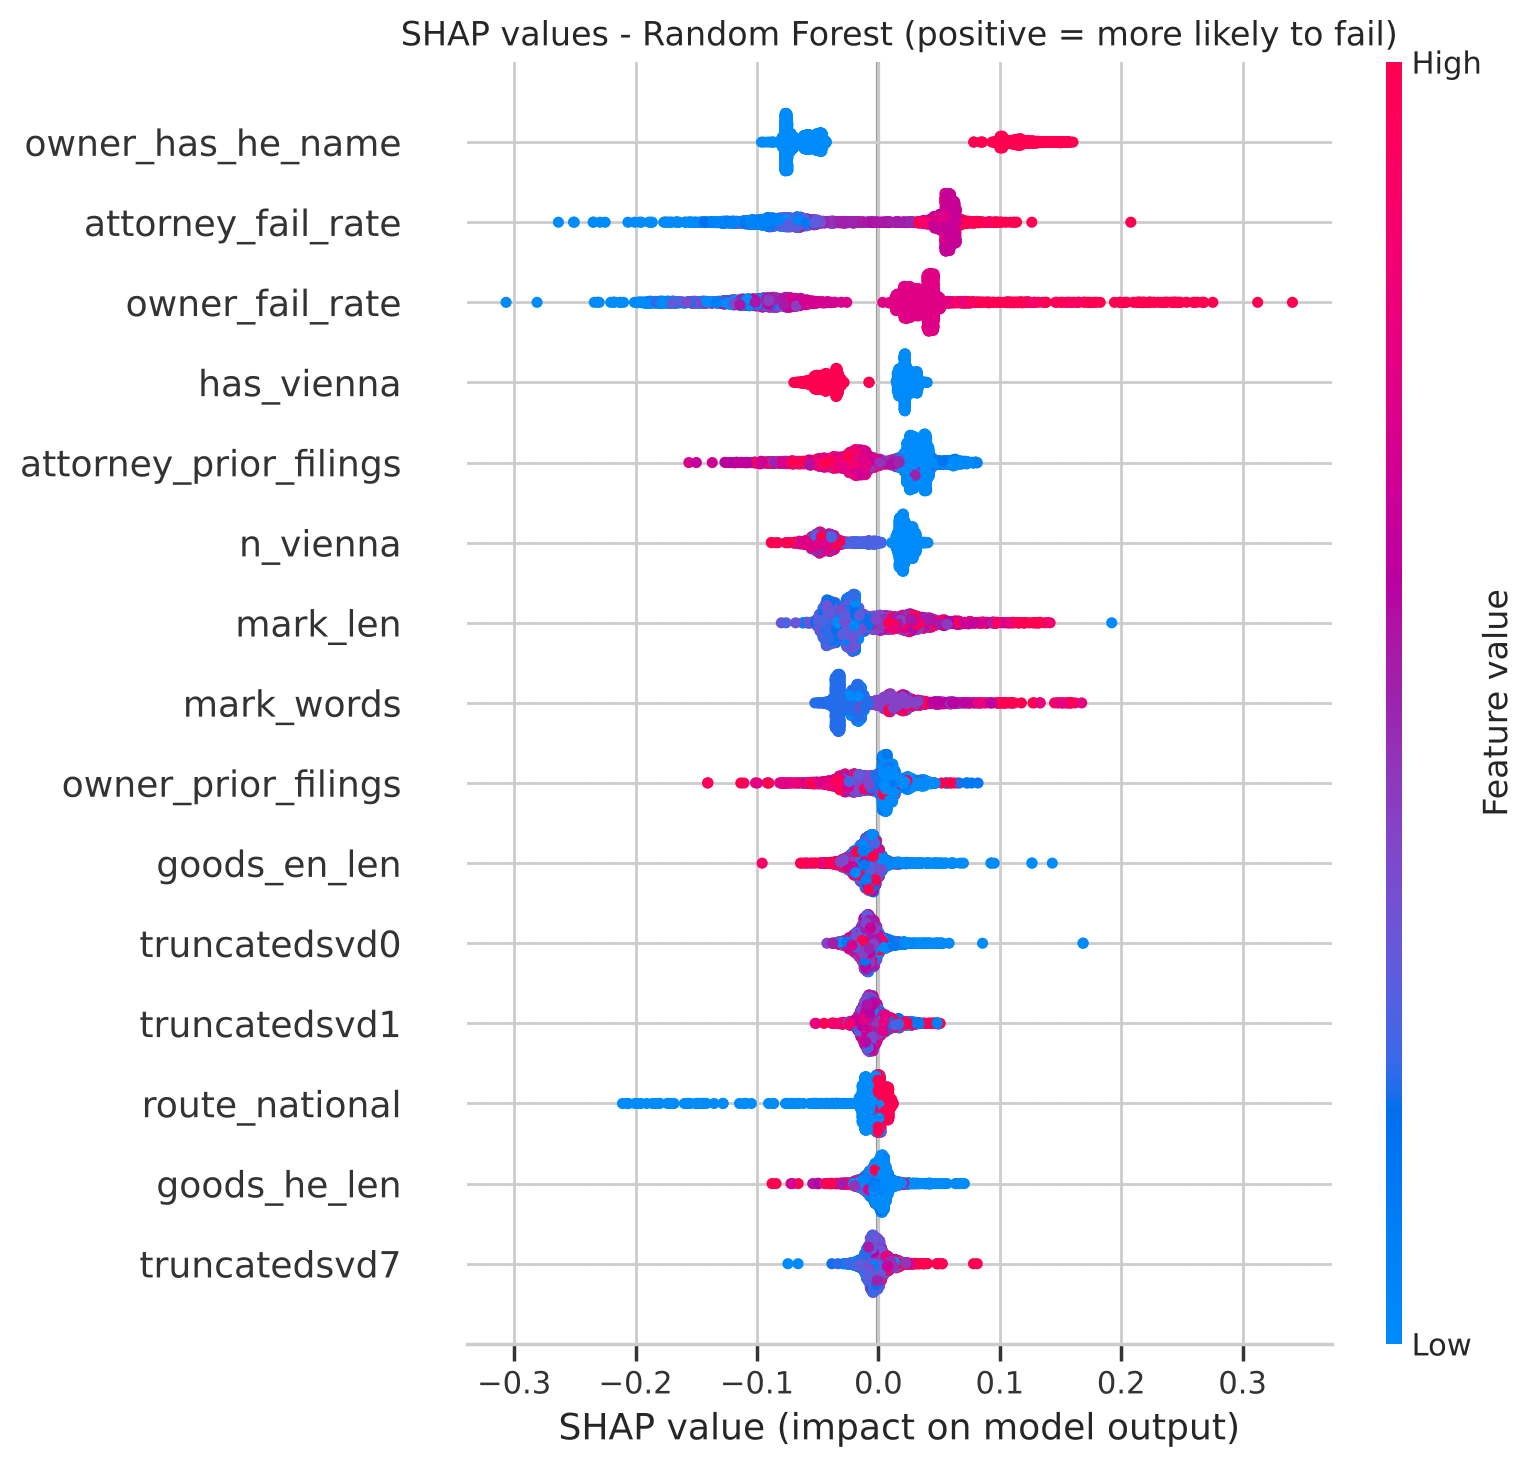

In [11]:
import shap

# SHAP on the same model as the permutation importance (tree models only)
shap_name = best_name if best_name in ["Random Forest", "LightGBM", "Decision Tree"] else "LightGBM"
shap_model = final[shap_name]
# exact SHAP on the deep Random Forest trees takes very long, so for it we use the fast approximation
# (Saabas values, approximate=True), which keeps the direction of each effect
approximate = shap_name == "Random Forest"
X_shap = shap_model.named_steps["pre"].transform(sample.head(3000)[X_cols])
names = [n.split("__", 1)[1] for n in shap_model.named_steps["pre"].get_feature_names_out()]
explainer = shap.TreeExplainer(shap_model.named_steps["model"])
shap_values = explainer.shap_values(X_shap, approximate=approximate, check_additivity=False)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif shap_values.ndim == 3:          # (rows, features, classes)
    shap_values = shap_values[:, :, 1]
shap.summary_plot(shap_values, X_shap, feature_names=names, max_display=15, show=False)
plt.title(f"SHAP values - {shap_name} (positive = more likely to fail)")
plt.tight_layout()
plt.savefig(FIG / "shap_summary.png", dpi=120, bbox_inches="tight")
plt.show()

**Importance.** For Random Forest the goods text is the most important input, followed by the Hebrew owner name,
the owner's past failure rate, the attorney's experience, the Vienna codes, the filing route and the attorney's failure rate.
The SHAP plot (same model) shows the directions: a Hebrew owner name, a high past failure rate of the owner or attorney,
and a longer mark text raise the risk; Vienna codes (figurative elements), an experienced attorney and an owner who filed
before lower it. The SHAP values for Random Forest are the fast approximation, so they show directions more than exact sizes.

## 8. Error analysis

In [12]:
threshold = results.loc[best_name, "threshold"]
pred = (probas[best_name] >= threshold).astype(int)
cm = confusion_matrix(y_test, pred)
print(f"{best_name}, threshold {threshold:.3f}")
pd.DataFrame(cm, index=["actual registered", "actual failed"], columns=["predicted registered", "predicted failed"])

Random Forest, threshold 0.446


,predicted registered,predicted failed
actual registered,35358,5131
actual failed,3933,2625


In [13]:
err = test.assign(pred=pred, proba=probas[best_name])

def group_metrics(col):
    rows = []
    for value, g in err.groupby(col):
        if len(g) < 300:
            continue
        tp = ((g["pred"] == 1) & (g["failed"] == 1)).sum()
        rows.append({col: value, "n": len(g), "failure_rate": g["failed"].mean(),
                     "precision": tp / max(g["pred"].sum(), 1), "recall": tp / max(g["failed"].sum(), 1),
                     "PR-AUC": average_precision_score(g["failed"], g["proba"]) if g["failed"].nunique() > 1 else np.nan})
    return pd.DataFrame(rows).set_index(col).round(3)

for col in ["filing_year", "route", "mark_script"]:
    display(group_metrics(col))

,n,failure_rate,precision,recall,PR-AUC
filing_year,,,,,
2019,11109,0.145,0.368,0.448,0.420
2020,11333,0.137,0.334,0.414,0.355
2021,12778,0.139,0.316,0.378,0.310
2022,11827,0.137,0.337,0.364,0.307


,n,failure_rate,precision,recall,PR-AUC
route,,,,,
base_for_international,1435,0.029,0.000,0.000,0.049
international,26173,0.123,0.325,0.290,0.297
national,19439,0.170,0.347,0.512,0.398


,n,failure_rate,precision,recall,PR-AUC
mark_script,,,,,
both,2269,0.278,0.373,0.777,0.525
hebrew,2343,0.195,0.394,0.681,0.492
latin,39692,0.132,0.324,0.341,0.313
none,2362,0.075,0.296,0.165,0.193
other,381,0.110,0.107,0.071,0.246


In [14]:
nice_cols = [c for c in err if c.startswith("nice_")]
rows = []
for c in nice_cols:
    g = err[err[c] == 1]
    if len(g) < 1000:
        continue
    tp = ((g["pred"] == 1) & (g["failed"] == 1)).sum()
    rows.append({"Nice class": int(c.split("_")[1]), "n": len(g), "failure_rate": g["failed"].mean(),
                 "recall": tp / max(g["failed"].sum(), 1), "PR-AUC": average_precision_score(g["failed"], g["proba"])})
by_class = pd.DataFrame(rows).set_index("Nice class").sort_values("PR-AUC").round(3)
pd.concat([by_class.head(5), by_class.tail(5)])

,n,failure_rate,recall,PR-AUC
Nice class,,,,
28,1794,0.084,0.351,0.229
34,1183,0.129,0.340,0.229
12,1978,0.108,0.192,0.230
14,1139,0.115,0.282,0.232
18,1604,0.093,0.248,0.246
38,1837,0.110,0.401,0.384
44,2147,0.122,0.456,0.388
29,1942,0.170,0.455,0.390
43,1855,0.165,0.572,0.442


**Errors.** Performance drops every year of the test period (PR-AUC 0.42 in 2019 down to 0.31 in 2022), which fits the
idea that the history features get older. National applications are predicted better than international ones (0.40 vs 0.30).
The "base for international" route almost never fails and the model flags none of them.
Hebrew marks are caught well (recall 0.68-0.78). The weakest Nice classes are 28 (toys), 34 (tobacco), 12 (vehicles),
14 (jewelry) and 18 (leather goods).

In [15]:
joblib.dump(best, OUT / f"best_model_{best_name.replace(' ', '_').lower()}.joblib", compress=3)
print("saved")

saved
